# Task 2: Unsupervised Machine Learning

I will use K-means to group similar traffic conditions. I will also use association rules to find links between time, day type, weather and congestion level.

No accident dataset is available, so the clustering will describe traffic conditions rather than accidents.

In [2]:
#Task 2: Unsupervised Machine Learning.
# Import packages and configure  logging.

import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

PART3_DIR = Path.cwd().parent
REPO_DIR = PART3_DIR.parent

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
    handlers=[
        logging.StreamHandler(),
        logging.FileHandler(
            PART3_DIR / "part3_unsupervised_ml.log",
            encoding="utf-8"
        )
    ],
    force=True
)

logger = logging.getLogger(__name__)

logger.info("Unsupervised learning notebook has been started.")

2026-10-10 22:47:51,680 | INFO | __main__ | Unsupervised learning notebook has been started.


## Load the cleaned traffic data

I woulduse the cleaned dataset from Part 2 to explore traffic conditions. It has 48187 records and 9 columns.This task describes patterns in historical data.

In [3]:
# Load and validate the cleaned Part 2 data.
import sys

part2_path = REPO_DIR / "part2_python"

if str(part2_path) not in sys.path:
    sys.path.insert(0, str(part2_path))

from pipeline import validate_schema, validate_cleaned_data

input_path = (
    part2_path / "data" / "traffic_cleaned.csv"
)

try:
    traffic_data = pd.read_csv(
        input_path,
        keep_default_na=False
    )


    
    validate_schema(traffic_data)

    traffic_data["date_time"] = pd.to_datetime(
        traffic_data["date_time"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )


    
    validate_cleaned_data(traffic_data)

    traffic_data = (
        traffic_data.sort_values("date_time", kind="stable")
        .reset_index(drop=True)
    )

    logger.info(
        "Cleaned traffic data ha beens loaded. There are %s rows and %s columns.",
        traffic_data.shape[0],
        traffic_data.shape[1]
    )

except (OSError, ValueError, TypeError, KeyError, pd.errors.ParserError):
    logger.error("Cleaned traffic data could not be loaded.", exc_info=True)
    raise




display(traffic_data.head())

2026-10-10 22:47:51,773 | INFO | pipeline | Column check has passed. All required columns are present.
2026-10-10 22:47:51,870 | INFO | pipeline | Cleaned data checks completed. There are 48187 rows and 9 columns.
2026-10-10 22:47:51,880 | INFO | __main__ | Cleaned traffic data ha beens loaded. There are 48187 rows and 9 columns.


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
#Prepare traffic-condition features for K-means.

traffic_data["hour"] = traffic_data["date_time"].dt.hour
traffic_data["day_of_week"] = (
    traffic_data["date_time"].dt.dayofweek
)


traffic_data["is_weekend"] = (
    traffic_data["day_of_week"] >= 5
).astype(int)

hour_angle = 2 * np.pi * traffic_data["hour"] / 24
traffic_data["hour_sin"] = np.sin(hour_angle)
traffic_data["hour_cos"] = np.cos(hour_angle)

weather_severity_map = {
    "Clear": 0,
    "Clouds": 0,
    "Rain": 1,
    "Drizzle": 1,
    "Fog": 1,
    "Mist": 1,
    "Haze": 1,
    "Smoke": 1,
    "Snow": 2,
    "Thunderstorm": 2,
    "Squall": 2
}

traffic_data["weather_severity"] = (
    traffic_data["weather_main"].map(weather_severity_map)
)

if traffic_data["weather_severity"].isna().any():
    raise ValueError(
        "Some weather categories do not have a severity score."
    )

cluster_features = [
    "hour_sin",
    "hour_cos",
    "weather_severity",
    "traffic_volume"
]

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(
    traffic_data[cluster_features]
)

assert np.isfinite(X_cluster).all()

logger.info(
    "Clustering inputs have been prepared with %s records and %s features.",
    X_cluster.shape[0],
    X_cluster.shape[1]
)



display(traffic_data[
    ["hour", "weather_main", "weather_severity", "traffic_volume"]
].head())

2026-10-10 22:47:51,940 | INFO | __main__ | Clustering inputs have been prepared with 48187 records and 4 features.


,hour,weather_main,weather_severity,traffic_volume
0,9,Clouds,0,5545
1,10,Clouds,0,4516
2,11,Clouds,0,4767
3,12,Clouds,0,5026
4,13,Clouds,0,4918


## Choose the number of clusters

I would compare K-means models with 2 to 6 clusters. The silhouette score measures how well records fit their own cluster compared with other clusters.

I would calculate the score on the same random sample of 3000 records for each model .

In [5]:
# Compare cluster counts using a fixed sample for silhouette scores.
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_cluster),
    size=min(3000, len(X_cluster)),
    replace=False
)

cluster_candidates = {}
cluster_results = []


for k in range(2, 7):
    logger.info("Training K-means with %s clusters.", k)

    candidate = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = candidate.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster[sample_indices],
        labels[sample_indices]
    )

    cluster_candidates[k] = candidate
    cluster_results.append({
        "clusters": k,
        "silhouette_score": score,
        "inertia": candidate.inertia_
    })

    logger.info(
        "K-means with %s clusters has silhouette score %.4f.",
        k,
        score
    )


cluster_comparison = pd.DataFrame(cluster_results)

best_k = int(
    cluster_comparison.loc[
        cluster_comparison["silhouette_score"].idxmax(),
        "clusters"
    ]
)



best_kmeans = cluster_candidates[best_k]
traffic_data["cluster"] = best_kmeans.labels_

logger.info("Selected K-means model with %s clusters.", best_k)

display(cluster_comparison.round(4))

2026-10-10 22:47:53,349 | INFO | __main__ | Training K-means with 2 clusters.
2026-10-10 22:47:56,539 | INFO | __main__ | K-means with 2 clusters has silhouette score 0.3563.
2026-10-10 22:47:56,540 | INFO | __main__ | Training K-means with 3 clusters.
2026-10-10 22:47:56,980 | INFO | __main__ | K-means with 3 clusters has silhouette score 0.3350.
2026-10-10 22:47:56,981 | INFO | __main__ | Training K-means with 4 clusters.
2026-10-10 22:47:57,369 | INFO | __main__ | K-means with 4 clusters has silhouette score 0.3502.
2026-10-10 22:47:57,370 | INFO | __main__ | Training K-means with 5 clusters.
2026-10-10 22:47:57,771 | INFO | __main__ | K-means with 5 clusters has silhouette score 0.3704.
2026-10-10 22:47:57,772 | INFO | __main__ | Training K-means with 6 clusters.
2026-10-10 22:47:58,191 | INFO | __main__ | K-means with 6 clusters has silhouette score 0.3670.
2026-10-10 22:47:58,194 | INFO | __main__ | Selected K-means model with 5 clusters.


,clusters,silhouette_score,inertia
0,2,0.3563,120374.5885
1,3,0.3350,93682.9050
2,4,0.3502,75749.4236
3,5,0.3704,61665.1355
4,6,0.3670,50987.4008


## Summarise the traffic clusters

Five clusters had the highest silhouette score of 0.3704 among the models tested with 2 to 6 clusters.

I wouold summarise each cluster using its record count, average traffic volume, average weather severity and percentage of weekend records. I would also show the most common hour and weather category.

In [6]:
# Summarise each cluster using the original feature values.

cluster_summary = (
    traffic_data.groupby("cluster")
    .agg(
        record_count=("traffic_volume", "size"),
        average_traffic_volume=("traffic_volume", "mean"),
        average_weather_severity=("weather_severity", "mean"),
        weekend_percentage=("is_weekend", lambda values: values.mean() * 100),
        most_common_hour=("hour", lambda values: values.mode().iloc[0]),
        most_common_weather=(
            "weather_main",
            lambda values: values.mode().iloc[0]
        )
    )
)


logger.info("Created summaries for %s clusters.", len(cluster_summary))

display(cluster_summary.round(2))

2026-10-10 22:48:06,128 | INFO | __main__ | Created summaries for 5 clusters.


,record_count,average_traffic_volume,average_weather_severity,weekend_percentage,most_common_hour,most_common_weather
cluster,,,,,,
0,8043,1079.69,1.24,33.26,4,Mist
1,12787,5080.17,0.00,23.28,14,Clouds
2,9624,3189.59,0.27,32.79,18,Clouds
3,9039,4924.87,1.22,20.38,9,Rain
4,8694,944.87,0.00,35.08,0,Clear


## Interpret the clusters

The five clusters describe different traffic conditions:

- Cluster 0 : It has low average traffic volume (1079.69), with Mist as its most common weather category and 04:00 as its most common hour.
- Cluster 1 : It has the highest average traffic volume (5080.17). Its weather severity is 0, with Clouds most common and 14:00  as its most common hour.
- Cluster 2: It  has intermediate average traffic volume (3189.59), relatively low average weather severity (0.27), and 18:00   as its most common hour.
- Cluster 3 : It  combines high average traffic volume (4924.87) with higher average weather severity (1.22). Rain is its most common weather category, and 09:00 is its most common hour.
- Cluster 4: It  has the lowest average traffic volume (944.87).  Its weather severity is 0, with Clear most common and midnight
  as its most common hour.

Clusters 1 and 3 contain higher-volume traffic conditions,while clusters 0 and 4 contain lower-volume conditions.


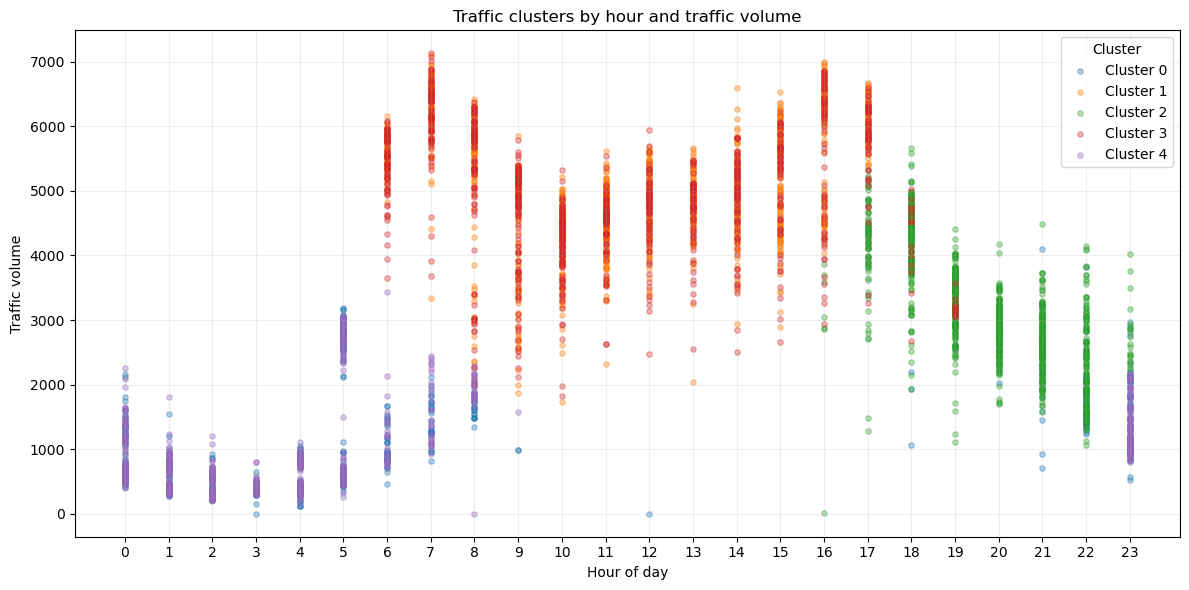

2026-10-10 22:51:11,854 | INFO | __main__ | Displayed the traffic cluster plot using 5000 records.


In [7]:
#Plot a sample of traffic records coloured by cluster.
import matplotlib.pyplot as plt

plot_data = traffic_data.sample(
    n=min(5000, len(traffic_data)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(12, 6))
colours = plt.get_cmap("tab10")

for cluster_id in sorted(traffic_data["cluster"].unique()):
    cluster_rows = plot_data.loc[
        plot_data["cluster"] == cluster_id
    ]

    ax.scatter(
        cluster_rows["hour"],
        cluster_rows["traffic_volume"],
        label=f"Cluster {cluster_id}",
        color=colours(int(cluster_id)),
        alpha=0.35,
        s=15
    )

ax.set_title("Traffic clusters by hour and traffic volume")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Traffic volume")
ax.set_xticks(range(24))
ax.legend(title="Cluster")
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


logger.info(
    "Displayed the traffic cluster plot using %s records.",
    len(plot_data)
)

In [8]:
#Prepare categorical data for association rules.

association_data = traffic_data[
    ["hour", "is_weekend", "weather_main", "traffic_volume"]
].copy()


association_data["time_period"] = pd.cut(
    association_data["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

association_data["day_type"] = np.where(
    association_data["is_weekend"].eq(1),
    "Weekend",
    "Weekday"
)

# Calculate quartiles for this historical association analysis.
q1_assoc, q2_assoc, q3_assoc = (
    association_data["traffic_volume"]
    .quantile([0.25, 0.50, 0.75])
    .to_numpy()
)

association_data["congestion_category"] = np.select(
    [
        association_data["traffic_volume"] <= q1_assoc,
        association_data["traffic_volume"] <= q2_assoc,
        association_data["traffic_volume"] <= q3_assoc
    ],
    ["Low", "Medium", "High"],
    default="Severe"
)


# Keep the four categorical attributes used in rule mining.
association_data = association_data[
    ["time_period", "day_type", "weather_main", "congestion_category"]
]

assert not association_data.isna().any().any()

logger.info(
    "Association categories have been prepared for %s records.",
    len(association_data)
)



display(pd.DataFrame({
    "boundary": ["25th percentile", "50th percentile", "75th percentile"],
    "traffic_volume": [q1_assoc, q2_assoc, q3_assoc]
}))

display(association_data.head())


2026-10-10 22:53:55,481 | INFO | __main__ | Association categories have been prepared for 48187 records.


,boundary,traffic_volume
0,25th percentile,1192.5
1,50th percentile,3379.0
2,75th percentile,4933.0


,time_period,day_type,weather_main,congestion_category
0,Morning,Weekday,Clouds,Severe
1,Morning,Weekday,Clouds,High
2,Morning,Weekday,Clouds,High
3,Afternoon,Weekday,Clouds,Severe
4,Afternoon,Weekday,Clouds,High


## Find association rules

I would examine combinations of time period, day type and weather that are associated with each congestion category.

Support is the proportion of all records containing both the conditions and the congestion category. Confidence is the proportion of records with those conditions that belong to the category.

I retain rules with at least 1% support, 60% confidence and lift greater than 1, then rank them by lift. 

In [9]:
#Calculate rules from combinations of the three context attributes.

from itertools import combinations

context_columns = ["time_period", "day_type", "weather_main"]

min_support = 0.01
min_confidence = 0.60
total_records = len(association_data)

category_support = (
    association_data["congestion_category"]
    .value_counts(normalize=True)
)

rule_records = []

for condition_count in range(1, len(context_columns) + 1):
    for condition_columns in combinations(
        context_columns, condition_count
    ):
        condition_columns = list(condition_columns)

        # Count records containing each combination of conditions.
        condition_counts = (
            association_data.groupby(
                condition_columns,
                observed=True
            )
            .size()
            .rename("antecedent_count")
            .reset_index()
        )


        
        joint_counts = (
            association_data.groupby(
                condition_columns + ["congestion_category"],
                observed=True
            )
            .size()
            .rename("joint_count")
            .reset_index()
        )

        counts = joint_counts.merge(
            condition_counts,
            on=condition_columns,
            validate="many_to_one"
        )

        for _, row in counts.iterrows():
            support = row["joint_count"] / total_records
            confidence = (
                row["joint_count"] / row["antecedent_count"]
            )
            consequent_support = category_support[
                row["congestion_category"]
            ]
            lift = confidence / consequent_support

            if (
                support >= min_support
                and confidence >= min_confidence
                and lift > 1
            ):
                conditions = " AND ".join(
                    f"{column}={row[column]}"
                    for column in condition_columns
                )

                rule_records.append({
                    "antecedent": conditions,
                    "consequent": (
                        "congestion_category="
                        f"{row['congestion_category']}"
                    ),
                    "antecedent_count": int(row["antecedent_count"]),
                    "joint_count": int(row["joint_count"]),
                    "support": support,
                    "confidence": confidence,
                    "consequent_support": consequent_support,
                    "lift": lift
                })

association_rules = pd.DataFrame(
    rule_records,
    columns=[
        "antecedent",
        "consequent",
        "antecedent_count",
        "joint_count",
        "support",
        "confidence",
        "consequent_support",
        "lift"
    ]
).sort_values(
    ["lift", "confidence", "support"],
    ascending=False
).reset_index(drop=True)


logger.info(
    "Found %s association rules meeting the selected thresholds.",
    len(association_rules)
)




if association_rules.empty:
    logger.warning(
        "No association rules met the selected thresholds."
    )
else:
    display(association_rules.head(10).round(4))
    

2026-10-10 22:56:28,527 | INFO | __main__ | Found 38 association rules meeting the selected thresholds.


,antecedent,consequent,antecedent_count,joint_count,support,confidence,consequent_support,lift
0,time_period=Night AND day_type=Weekend AND wea...,congestion_category=Low,558,511,0.0106,0.9158,0.2500,3.6630
1,time_period=Night AND day_type=Weekend,congestion_category=Low,3503,3104,0.0644,0.8861,0.2500,3.5443
2,time_period=Night AND day_type=Weekend AND wea...,congestion_category=Low,750,663,0.0138,0.8840,0.2500,3.5359
3,time_period=Night AND weather_main=Snow,congestion_category=Low,745,648,0.0134,0.8698,0.2500,3.4791
4,time_period=Night AND day_type=Weekend AND wea...,congestion_category=Low,1227,1059,0.0220,0.8631,0.2500,3.4523
5,time_period=Night AND weather_main=Clouds,congestion_category=Low,2782,2372,0.0492,0.8526,0.2500,3.4104
6,time_period=Night AND weather_main=Clear,congestion_category=Low,3939,3353,0.0696,0.8512,0.2500,3.4049
7,time_period=Night,congestion_category=Low,12281,10424,0.2163,0.8488,0.2500,3.3951
8,time_period=Afternoon AND day_type=Weekend AND...,congestion_category=High,1381,1170,0.0243,0.8472,0.2502,3.3868
9,time_period=Night AND day_type=Weekday AND wea...,congestion_category=Low,2712,2294,0.0476,0.8459,0.2500,3.3834


In [10]:
#Display full conditions and explain the highest-lift rules.
top_rules = association_rules.head(5).copy()

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None
):
    display(top_rules.round(4))

rule_explanations = []

for rank, (_, rule) in enumerate(top_rules.iterrows(), start=1):
    conditions = (
        rule["antecedent"]
        .replace("time_period=", "time period: ")
        .replace("day_type=", "day type: ")
        .replace("weather_main=", "weather: ")
        .replace(" AND ", "; ")
    )

    category = rule["consequent"].split("=", 1)[1]

    rule_explanations.append({
        "rank": rank,
        "explanation": (
            f"When {conditions}, "
            f"{rule['confidence']:.1%} of matching records "
            f"have {category} congestion category "
            f"({int(rule['joint_count'])} of "
            f"{int(rule['antecedent_count'])} records). "
            f"This is {rule['lift']:.2f} times the category's "
            f"overall frequency. The rule covers "
            f"{rule['support']:.1%} of all records."
        )
    })

rule_explanations = pd.DataFrame(rule_explanations)

with pd.option_context("display.max_colwidth", None):
    display(rule_explanations)

logger.info(
    "Prepared explanations for the %s highest-lift rul es.",
    len(top_rules)
)






,antecedent,consequent,antecedent_count,joint_count,support,confidence,consequent_support,lift
0,time_period=Night AND day_type=Weekend AND weather_main=Mist,congestion_category=Low,558,511,0.0106,0.9158,0.25,3.6630
1,time_period=Night AND day_type=Weekend,congestion_category=Low,3503,3104,0.0644,0.8861,0.25,3.5443
2,time_period=Night AND day_type=Weekend AND weather_main=Clouds,congestion_category=Low,750,663,0.0138,0.8840,0.25,3.5359
3,time_period=Night AND weather_main=Snow,congestion_category=Low,745,648,0.0134,0.8698,0.25,3.4791
4,time_period=Night AND day_type=Weekend AND weather_main=Clear,congestion_category=Low,1227,1059,0.0220,0.8631,0.25,3.4523


,rank,explanation
0,1,"When time period: Night; day type: Weekend; weather: Mist, 91.6% of matching records have Low congestion category (511 of 558 records). This is 3.66 times the category's overall frequency. The rule covers 1.1% of all records."
1,2,"When time period: Night; day type: Weekend, 88.6% of matching records have Low congestion category (3104 of 3503 records). This is 3.54 times the category's overall frequency. The rule covers 6.4% of all records."
2,3,"When time period: Night; day type: Weekend; weather: Clouds, 88.4% of matching records have Low congestion category (663 of 750 records). This is 3.54 times the category's overall frequency. The rule covers 1.4% of all records."
3,4,"When time period: Night; weather: Snow, 87.0% of matching records have Low congestion category (648 of 745 records). This is 3.48 times the category's overall frequency. The rule covers 1.3% of all records."
4,5,"When time period: Night; day type: Weekend; weather: Clear, 86.3% of matching records have Low congestion category (1059 of 1227 records). This is 3.45 times the category's overall frequency. The rule covers 2.2% of all records."


2026-10-10 22:57:51,834 | INFO | __main__ | Prepared explanations for the 5 highest-lift rul es.


## Save the unsupervised learning outputs

I would save the selected K-means model, scaler and preparation settings so the clustering can be reused. I would also save the cluster comparison, cluster summaries, association rules, explanations and trafic cluster chart.

In [11]:
#Save the Task 2 models, settings, result tables and chart.
import joblib

models_dir = PART3_DIR / "models"
results_dir = PART3_DIR / "results"
figures_dir = PART3_DIR / "figures"

for directory in [models_dir, results_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)

# Save the fitted model and scaler.
joblib.dump(
    best_kmeans,
    models_dir / "kmeans_traffic_v1.joblib",
    compress=3
)

joblib.dump(
    cluster_scaler,
    models_dir / "cluster_scaler_v1.joblib",
    compress=3
)

#Save settings needed to reproduce the feature preparation.
unsupervised_config = {
    "cluster_features": cluster_features,
    "weather_severity_map": weather_severity_map,
    "selected_clusters": best_k,
    "random_state": 42,
    "n_init": 10,
    "silhouette_sample_size": len(sample_indices),
    "time_period_bins": [-1, 5, 11, 17, 23],
    "time_period_labels": [
        "Night", "Morning", "Afternoon", "Evening"
    ],
    "congestion_thresholds": [
        float(q1_assoc),
        float(q2_assoc),
        float(q3_assoc)
    ],
    "min_support": min_support,
    "min_confidence": min_confidence,
    "min_lift_exclusive": 1.0
}



joblib.dump(
    unsupervised_config,
    models_dir / "unsupervised_config_v1.joblib",
    compress=3
)

logger.info("Saved the clustering model, scaler and settings.")



# Save the result tables.
result_tables = {
    "cluster_comparison": cluster_comparison,
    "cluster_summary": cluster_summary.reset_index(),
    "association_rules": association_rules,
    "association_rule_explanations": rule_explanations
}


for filename, table in result_tables.items():
    table.to_csv(
        results_dir / f"{filename}.csv",
        index=False
    )

    logger.info(
        "Saved Task 2 results to results/%s.csv.",
        filename
    )

# Save the scatter plot created 
fig.savefig(
    figures_dir / "traffic_clusters.png",
    dpi=150,
    bbox_inches="tight"
)

logger.info("Saved the traffic cluster chart.")

# Check that reloaded artifacts preserve cluster assignments.
loaded_kmeans = joblib.load(
    models_dir / "kmeans_traffic_v1.joblib"
)
loaded_scaler = joblib.load(
    models_dir / "cluster_scaler_v1.joblib"
)




sample_features = traffic_data[cluster_features].head(100)

original_labels = best_kmeans.predict(
    cluster_scaler.transform(sample_features)
)
reloaded_labels = loaded_kmeans.predict(
    loaded_scaler.transform(sample_features)
)



np.testing.assert_array_equal(
    original_labels,
    reloaded_labels
)

logger.info("The clustering model and scaler passed the reload check.")



2026-10-10 23:00:34,365 | INFO | __main__ | Saved the clustering model, scaler and settings.
2026-10-10 23:00:34,375 | INFO | __main__ | Saved Task 2 results to results/cluster_comparison.csv.
2026-10-10 23:00:34,378 | INFO | __main__ | Saved Task 2 results to results/cluster_summary.csv.
2026-10-10 23:00:34,381 | INFO | __main__ | Saved Task 2 results to results/association_rules.csv.
2026-10-10 23:00:34,384 | INFO | __main__ | Saved Task 2 results to results/association_rule_explanations.csv.
2026-10-10 23:00:34,950 | INFO | __main__ | Saved the traffic cluster chart.
2026-10-10 23:00:34,990 | INFO | __main__ | The clustering model and scaler passed the reload check.
